# Maverick Detection in the Danish Parliament

**DTU 02807 · Group project · Task 4**

**Research question:** *Which MPs vote more like another party than their own?*

This notebook implements a reproducible **direct voting-agreement baseline**, investigates **within-party dissent**, and produces three publication-ready figures. It uses the latest `votes.csv` and does not modify the shared dataset.

**Reading guide:** Each section describes the question, the method, and the output. Run cells from top to bottom. All numerical results are recalculated from the current CSV; earlier results should not be copied into the report.

## 1. Setup and analysis choices

`vote` codes: **1 = For**, **2 = Against**, **3 = Absent**, **4 = Abstain**. The default analysis uses **1 and 2 only**, consistent with the group's binary pairwise-similarity convention. Abstentions and absences remain in the original dataset but do not contribute to agreement. To reproduce the earlier three-category baseline, change `VALID_VOTES` to `(1, 2, 4)` and rerun all cells.

`MIN_SHARED_VOTES = 100` is a **pair-specific reliability threshold**: each MP–other-party comparison must contain at least 100 shared, comparable sessions. It is distinct from any MP-level preprocessing threshold applied by `retrieve.ipynb`. A sensitivity check later explores alternative thresholds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("votes.csv")
VALID_VOTES = (1, 2)  # Binary votes; change to (1, 2, 4) for the earlier baseline
MIN_SHARED_VOTES = 100
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(f"Rows: {len(df):,} | MPs: {df.actor.nunique()} | Sessions: {df.session.nunique()}")
print("Vote counts:")
display(df.vote.value_counts().sort_index().rename("records"))

Rows: 219,411 | MPs: 197 | Sessions: 1302
Vote counts:


vote
1    74703
2    63004
3    79314
4     2390
Name: records, dtype: int64

## 2. Data checks and participation

The source CSV may already exclude MPs with too few non-absent votes. We **do not remove further MPs here**. A CSV row is **not** necessarily participation: `vote == 3` means absence. The two participation definitions below make this distinction explicit.

We also check that each `(session, actor)` occurs at most once and record how many MPs have more than one party label over time.

In [2]:
assert {"session", "actor", "party", "vote", "date"}.issubset(df.columns)
assert df.vote.dropna().isin([1, 2, 3, 4]).all(), "Unexpected vote code"
duplicates = df.duplicated(["session", "actor"]).sum()
print("Duplicate MP-session records:", duplicates)
assert duplicates == 0, "Resolve duplicate MP-session rows before continuing"
print("Missing party labels:", df.party.isna().sum())
print("MPs with multiple party labels:", (df.groupby("actor").party.nunique() > 1).sum())

participation = df.groupby("actor").agg(
    recorded_sessions=("session", "nunique"),
    binary_votes=("vote", lambda s: s.isin([1, 2]).sum()),
    non_absent_votes=("vote", lambda s: s.isin([1, 2, 4]).sum()),
)
participation["observed_attendance"] = participation.non_absent_votes / participation.recorded_sessions
print("\nParticipation summary (per MP):")
display(participation.describe(percentiles=[.10, .25, .50, .75, .90]).round(3))

Duplicate MP-session records: 0
Missing party labels: 128
MPs with multiple party labels: 12

Participation summary (per MP):


,recorded_sessions,binary_votes,non_absent_votes,observed_attendance
count,197.000,197.000,197.000,197.000
mean,1113.761,699.020,711.152,0.655
std,346.055,293.397,295.881,0.193
min,117.000,108.000,109.000,0.084
10%,418.800,224.800,231.400,0.371
25%,1084.000,481.000,481.000,0.552
50%,1302.000,767.000,794.000,0.678
75%,1302.000,922.000,932.000,0.786
90%,1302.000,1026.200,1040.600,0.885
max,1302.000,1201.000,1204.000,0.979


## 3. Party majorities by session

For each party and session, count valid votes and identify the most frequent voting category. **Ties produce an undefined majority** and are excluded from subsequent comparisons. A party with no valid votes in a session has no majority row.

`unstack()` converts the voting categories into count columns (one column per vote type).

In [3]:
df_valid = df.loc[df.vote.isin(VALID_VOTES) & df.party.notna()].copy()
party_counts = (
    df_valid.groupby(["session", "party", "vote"]).size()
    .unstack(fill_value=0)
    .reindex(columns=list(VALID_VOTES), fill_value=0)
)
max_count = party_counts.max(axis=1)
tied = party_counts.eq(max_count, axis=0).sum(axis=1).gt(1)
party_majority = (party_counts.idxmax(axis=1).mask(tied)
                  .rename("majority_vote").reset_index())
print("Party-session combinations:", len(party_majority))
print("Undefined party majorities:", party_majority.majority_vote.isna().sum())
display(party_majority.head())

Party-session combinations: 17067
Undefined party majorities: 8


,session,party,majority_vote
0,9002,Alternativet,1.0
1,9002,Danmarksdemokraterne – Inger Støjberg,1.0
2,9002,Dansk Folkeparti,1.0
3,9002,Det Konservative Folkeparti,1.0
4,9002,Enhedslisten,1.0


## 4. Leave-one-out agreement with the MP's own party

A politician must **not influence the majority used to assess their own vote**. We therefore subtract the MP's vote from the corresponding party counts before computing the majority of the *remaining* party members. If no votes remain or the remaining votes are tied, the comparison is undefined.

This avoids self-agreement, especially in small parties.

In [4]:
df_loo = df_valid.merge(party_counts.reset_index(), on=["session", "party"], how="left", validate="many_to_one")
for v in VALID_VOTES:
    df_loo[v] -= df_loo.vote.eq(v).astype(int)
remaining = df_loo[list(VALID_VOTES)]
remaining_max = remaining.max(axis=1)
remaining_tie = remaining.eq(remaining_max, axis=0).sum(axis=1).gt(1)
df_loo["own_party_majority"] = remaining.idxmax(axis=1).mask(remaining_tie | remaining_max.eq(0))

df_agreement = df_loo.dropna(subset=["own_party_majority"]).copy()
df_agreement["agrees_with_own"] = df_agreement.vote.eq(df_agreement.own_party_majority)
print("Valid individual leave-one-out comparisons:", len(df_agreement))
print("Total dissenting votes:", (~df_agreement.agrees_with_own).sum())
print("Overall dissent rate: {:.3%}".format((~df_agreement.agrees_with_own).mean()))

Valid individual leave-one-out comparisons: 134475
Total dissenting votes: 166
Overall dissent rate: 0.123%


## 5. Cross-party voting agreement and Maverick Score

Compare each MP with **every other party that has a defined majority in the same session**. The own-party and other-party agreement rates are computed over the **exact same shared sessions**, so their denominators match.

For MP \(i\), own party \(p\), and comparison party \(q\):

\[
M(i,p,q)=A(i,q)-A(i,p),\qquad M(i,p)=\max_{q\ne p}M(i,p,q).
\]

**Positive**: more agreement with another party; **Zero**: equally high agreement; **Negative**: own-party agreement exceeds all eligible other-party comparisons. These are *descriptive labels*, not judgments about politicians. Party changes are handled by grouping separately by `(actor, party)`; repeated non-contiguous membership periods in the same party are not separated.

In [5]:
other_majorities = party_majority.rename(columns={"party": "other_party", "majority_vote": "other_majority"})
df_cross = (
    df_agreement[["session", "actor", "party", "vote", "own_party_majority", "agrees_with_own"]]
    .merge(other_majorities, on="session", how="inner")
)
df_cross = df_cross.loc[
    df_cross.party.ne(df_cross.other_party) & df_cross.other_majority.notna()
].copy()
df_cross["agrees_with_other"] = df_cross.vote.eq(df_cross.other_majority)

cross_scores_all = (
    df_cross.groupby(["actor", "party", "other_party"], as_index=False)
    .agg(own_agreement=("agrees_with_own", "mean"),
         other_agreement=("agrees_with_other", "mean"),
         n_shared_votes=("session", "nunique"))
)
cross_scores_all["maverick_score"] = cross_scores_all.other_agreement - cross_scores_all.own_agreement
print("All MP–own-party–other-party comparisons:", len(cross_scores_all))

All MP–own-party–other-party comparisons: 3808


## 6. Best-matching other party and classification

Apply the minimum **shared-vote** threshold, then retain the highest-scoring comparison for each `(actor, party)`. If several other parties tie, the displayed party is just one of the tied matches; it should not be interpreted as a unique political affiliation. Some MP-party combinations may have no eligible comparison and will be absent from the final table.

In [6]:
eligible_scores = cross_scores_all.loc[cross_scores_all.n_shared_votes >= MIN_SHARED_VOTES].copy()
best_matches = (
    eligible_scores.sort_values(["actor", "party", "maverick_score", "other_party"],
                                ascending=[True, True, False, True])
    .drop_duplicates(["actor", "party"])
    .sort_values("maverick_score", ascending=False)
    .reset_index(drop=True)
)
best_matches["classification"] = np.select(
    [best_matches.maverick_score > 1e-12, best_matches.maverick_score < -1e-12],
    ["Positive", "Negative"], default="Zero"
)
summary = best_matches.classification.value_counts().reindex(["Positive", "Zero", "Negative"], fill_value=0)
print("Unique MPs:", best_matches.actor.nunique())
print("MP-party combinations:", len(best_matches))
display(summary.rename("MP-party combinations"))
display(best_matches.maverick_score.describe().rename("Maverick score"))
display(best_matches.head(12))

Unique MPs: 194
MP-party combinations: 197


classification
Positive      1
Zero         91
Negative    105
Name: MP-party combinations, dtype: int64

count    197.000000
mean      -0.066416
std        0.070504
min       -0.222222
25%       -0.131783
50%       -0.003040
75%        0.000000
max        0.001075
Name: Maverick score, dtype: float64

,actor,party,other_party,own_agreement,other_agreement,n_shared_votes,maverick_score,classification
0,201,Socialdemokratiet,Moderaterne,0.998925,1.000000,930,0.001075,Positive
1,38,Socialdemokratiet,"Venstre, Danmarks Liberale Parti",1.000000,1.000000,660,0.000000,Zero
2,74,Socialdemokratiet,Moderaterne,1.000000,1.000000,663,0.000000,Zero
3,49,"Venstre, Danmarks Liberale Parti",Socialdemokratiet,1.000000,1.000000,1052,0.000000,Zero
4,12,Socialdemokratiet,Moderaterne,1.000000,1.000000,171,0.000000,Zero
5,1619,Socialdemokratiet,"Venstre, Danmarks Liberale Parti",1.000000,1.000000,113,0.000000,Zero
6,286,Socialdemokratiet,"Venstre, Danmarks Liberale Parti",1.000000,1.000000,1023,0.000000,Zero
7,278,Socialdemokratiet,Moderaterne,1.000000,1.000000,579,0.000000,Zero
8,57,Moderaterne,Socialdemokratiet,1.000000,1.000000,377,0.000000,Zero
9,93,"Venstre, Danmarks Liberale Parti",Socialdemokratiet,0.998924,0.998924,929,0.000000,Zero


## 7. Figure 1 — Distribution of Maverick Scores

This is the primary result: scores **above zero** indicate more agreement with at least one other party than with the MP's own party. A spike at zero means equal agreement, not political neutrality.

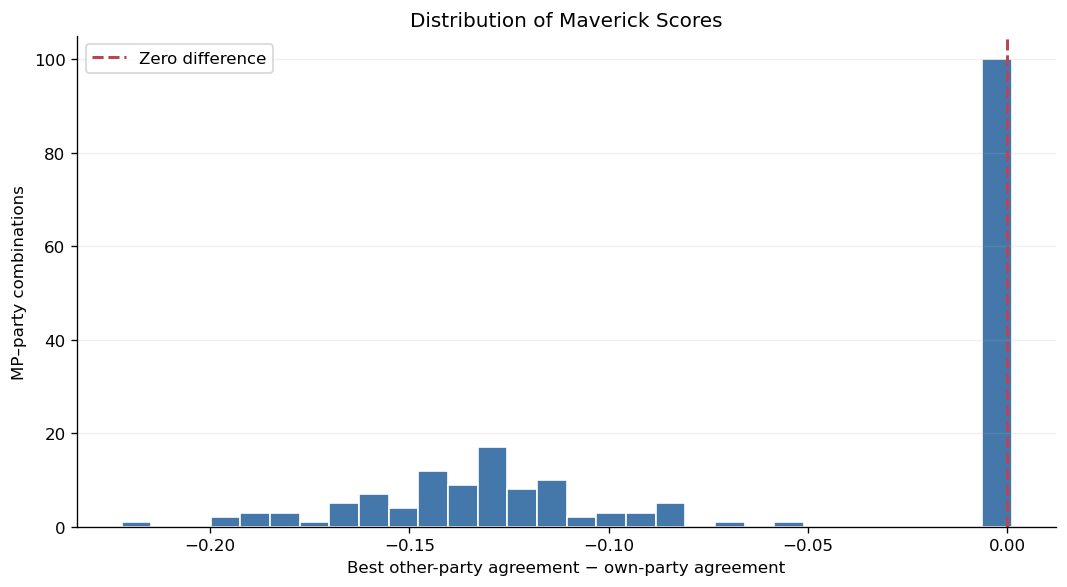

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(best_matches.maverick_score, bins=30, color="#4477AA", edgecolor="white")
ax.axvline(0, color="#BB4455", linestyle="--", linewidth=1.8, label="Zero difference")
ax.set(title="Distribution of Maverick Scores", xlabel="Best other-party agreement − own-party agreement", ylabel="MP–party combinations")
ax.legend(); ax.grid(axis="y", alpha=.2)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "maverick_score_distribution.pdf", bbox_inches="tight")
plt.show()

## 8. Figure 2 — Classification counts

Counts are **MP-party combinations**, not necessarily unique MPs. The labels are based on the sign of the score; they do not establish statistically meaningful differences.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#CC9966", "#999999", "#4477AA"]
bars = ax.bar(summary.index, summary.values, color=colors)
ax.bar_label(bars, padding=3)
ax.set(title="Maverick Classification", ylabel="MP–party combinations")
ax.set_ylim(0, max(summary.max() * 1.15, 1)); ax.grid(axis="y", alpha=.2)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "maverick_classification.pdf", bbox_inches="tight")
plt.show()

## 9. Within-party dissent rates

As a complementary measure, calculate the fraction of individual votes that disagree with the **leave-one-out** majority of the MP's own party. This is **not** the Maverick Score: it measures internal party disagreement, not alignment with another party. Smaller parties may have more undefined leave-one-out majorities; comparisons therefore require caution.

In [8]:
party_dissent = (
    df_agreement.assign(dissent=~df_agreement.agrees_with_own)
    .groupby("party", as_index=False)
    .agg(n_mps=("actor", "nunique"), n_comparable=("dissent", "size"), n_dissent=("dissent", "sum"))
)
party_dissent["dissent_rate"] = party_dissent.n_dissent / party_dissent.n_comparable
party_dissent = party_dissent.sort_values("dissent_rate", ascending=False)
display(party_dissent)

,party,n_mps,n_comparable,n_dissent,dissent_rate
4,Enhedslisten,12,6245,37,0.005925
2,Dansk Folkeparti,7,4728,17,0.003596
8,Radikale Venstre,7,4997,10,0.002001
1,Danmarksdemokraterne – Inger Støjberg,16,11385,22,0.001932
3,Det Konservative Folkeparti,13,7266,12,0.001652
10,Socialistisk Folkeparti,17,11347,17,0.001498
5,Liberal Alliance,15,11476,17,0.001481
6,Moderaterne,19,10411,12,0.001153
0,Alternativet,10,3926,4,0.001019
11,"Venstre, Danmarks Liberale Parti",26,19642,13,0.000662


## 10. Figure 3 — Party-level dissent rates

The figure shows the percentage of **comparable individual votes** that deviate from each party's leave-one-out majority. Parties with fewer than 100 comparable observations are omitted from this plot only, not from the data or other analyses.

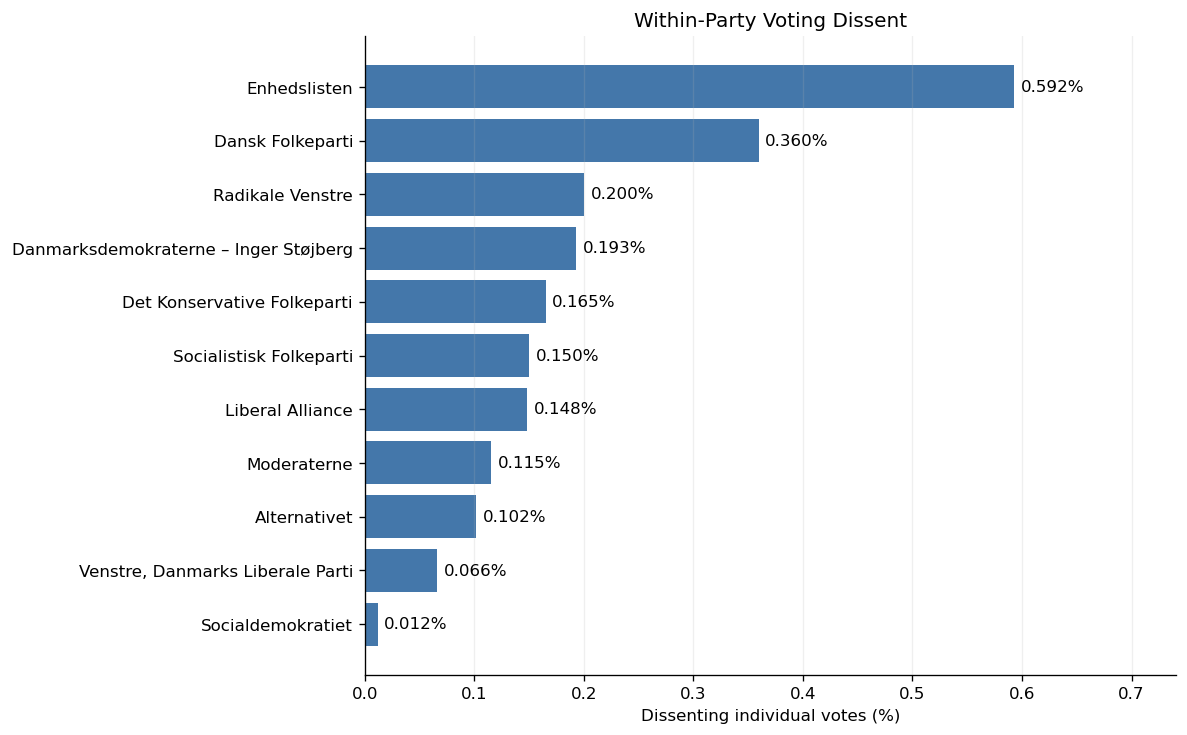

In [9]:
plot_data = party_dissent.loc[party_dissent.n_comparable >= 100].sort_values("dissent_rate").copy()
plot_data["dissent_percent"] = 100 * plot_data.dissent_rate
fig, ax = plt.subplots(figsize=(10, max(5, .43 * len(plot_data) + 1.5)))
bars = ax.barh(plot_data.party, plot_data.dissent_percent, color="#4477AA")
ax.bar_label(bars, fmt="%.3f%%", padding=4)
ax.set(title="Within-Party Voting Dissent", xlabel="Dissenting individual votes (%)")
ax.set_xlim(0, max(plot_data.dissent_percent.max() * 1.25, .01)); ax.grid(axis="x", alpha=.2)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "party_dissent_rates.pdf", bbox_inches="tight")
plt.show()

## 11. Sensitivity analysis — does the cutoff matter?

Rather than choosing a threshold to obtain a desired number of Mavericks, recompute the classification at several **minimum shared-vote** thresholds. This is a sensitivity check, not a new MP attendance filter. The original `cross_scores_all` is retained so the threshold can be changed without rebuilding the pipeline.

In [10]:
sensitivity_rows = []
for threshold in [50, 100, 200, 400]:
    eligible = cross_scores_all.loc[cross_scores_all.n_shared_votes >= threshold]
    best = (eligible.sort_values("maverick_score", ascending=False)
            .drop_duplicates(["actor", "party"]))
    sensitivity_rows.append({
        "min_shared_votes": threshold,
        "n_mps": best.actor.nunique(),
        "n_mp_party": len(best),
        "positive": int((best.maverick_score > 1e-12).sum()),
        "zero": int(best.maverick_score.abs().le(1e-12).sum()),
        "negative": int((best.maverick_score < -1e-12).sum()),
    })
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

,min_shared_votes,n_mps,n_mp_party,positive,zero,negative
0,50,195,198,1,100,97
1,100,194,197,1,91,105
2,200,177,178,1,81,96
3,400,152,152,1,71,80


## 12. Inspect positive cases and export results

If any positive scores exist, show the underlying **sessions** where an MP agreed with the other party but not with their own. Do not hard-code actor IDs: the identity of a positive case may change when the shared CSV or voting-category convention changes.

To identify a person by name, use the group's verified actor metadata or the official Folketinget actor API; the numeric `actor` field alone is not a name.

In [11]:
positive_cases = best_matches.loc[best_matches.classification.eq("Positive")]
print("Positive MP-party combinations:", len(positive_cases))
display(positive_cases[["actor", "party", "other_party", "n_shared_votes", "maverick_score"]])

if not positive_cases.empty:
    examples = df_cross.merge(
        positive_cases[["actor", "party", "other_party"]],
        on=["actor", "party", "other_party"], how="inner"
    )
    examples = examples.loc[~examples.agrees_with_own & examples.agrees_with_other]
    display(examples[["session", "actor", "party", "other_party", "vote", "own_party_majority", "other_majority"]].head(30))

best_matches.to_csv("maverick_results.csv", index=False)
party_dissent.to_csv("party_dissent_results.csv", index=False)
sensitivity.to_csv("maverick_sensitivity.csv", index=False)
print("Saved three CSV tables and three PDF figures.")

Positive MP-party combinations: 1


,actor,party,other_party,n_shared_votes,maverick_score
0,201,Socialdemokratiet,Moderaterne,930,0.001075


,session,actor,party,other_party,vote,own_party_majority,other_majority
925,10373,201,Socialdemokratiet,Moderaterne,2,1,2.0


Saved three CSV tables and three PDF figures.
